# 02 · Models — does a model trained before the war survive it?

Backtest produced by `python -m src.backtest` (walk-forward, every day forecast only from data available before the
12:00 CET auction on D-1). Two test windows:

* **normal** — 1 Mar 2025 – 27 Feb 2026 (control year);
* **crisis** — 28 Feb 2026 (start of the Iran war) – today.

Model variants: `naive` (same hour a week ago) · `ridge` / `lgbm` · `base` (calendar + TSO forecasts + price lags) vs
`gas` (+ TTF, CO₂ proxy, storage) · `static` (trained once before the window) vs `rolling` (retrained every 7 days).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR
from src import plots
from src.plots import PRE, CRISIS, THIRD, MUTED, INK_2

plots.setup()
save = lambda fig, name: fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")
pred = pd.read_parquet(PROCESSED_DIR / "predictions.parquet")
metrics = pd.read_csv(REPORTS_DIR / "metrics.csv")
battery = pd.read_csv(REPORTS_DIR / "battery.csv")

## 1. Accuracy: normal year vs crisis (MAE, €/MWh)

In [2]:
table = metrics.pivot(index="model", columns="period", values="MAE")[["normal", "crisis"]]
table["crisis / normal"] = table["crisis"] / table["normal"]
table.sort_values("crisis").round(2)

period,normal,crisis,crisis / normal
model,,,
lgbm_gas_rolling,11.77,17.38,1.48
ridge_gas_rolling,15.00,18.98,1.27
lgbm_base_rolling,12.56,21.20,1.69
ridge_gas_static,16.13,21.39,1.33
ridge_base_rolling,15.38,25.60,1.66
ridge_base_static,15.72,29.79,1.90
lgbm_gas_static,15.58,30.94,1.99
lgbm_base_static,13.75,31.04,2.26
naive,29.21,42.92,1.47


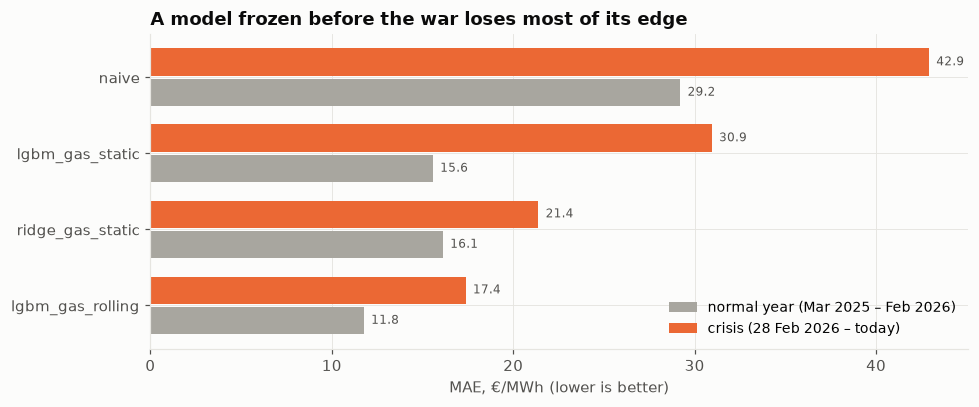

In [3]:
show = ["naive", "lgbm_gas_static", "ridge_gas_static", "lgbm_gas_rolling"]
colors = {"naive": MUTED, "lgbm_gas_static": PRE, "ridge_gas_static": THIRD, "lgbm_gas_rolling": CRISIS}
t = table.loc[show, ["normal", "crisis"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(show))
ax.barh(y + 0.2, t["normal"], height=0.36, color=MUTED, label="normal year (Mar 2025 – Feb 2026)")
ax.barh(y - 0.2, t["crisis"], height=0.36, color=CRISIS, label="crisis (28 Feb 2026 – today)")
for yi, (n, c) in enumerate(zip(t["normal"], t["crisis"])):
    ax.text(n + 0.4, yi + 0.2, f"{n:.1f}", va="center", fontsize=8, color=INK_2)
    ax.text(c + 0.4, yi - 0.2, f"{c:.1f}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, show); ax.invert_yaxis()
ax.set_xlabel("MAE, €/MWh (lower is better)")
ax.set_title("A model frozen before the war loses most of its edge")
ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "07_mae_normal_vs_crisis")

## 2. Error month by month

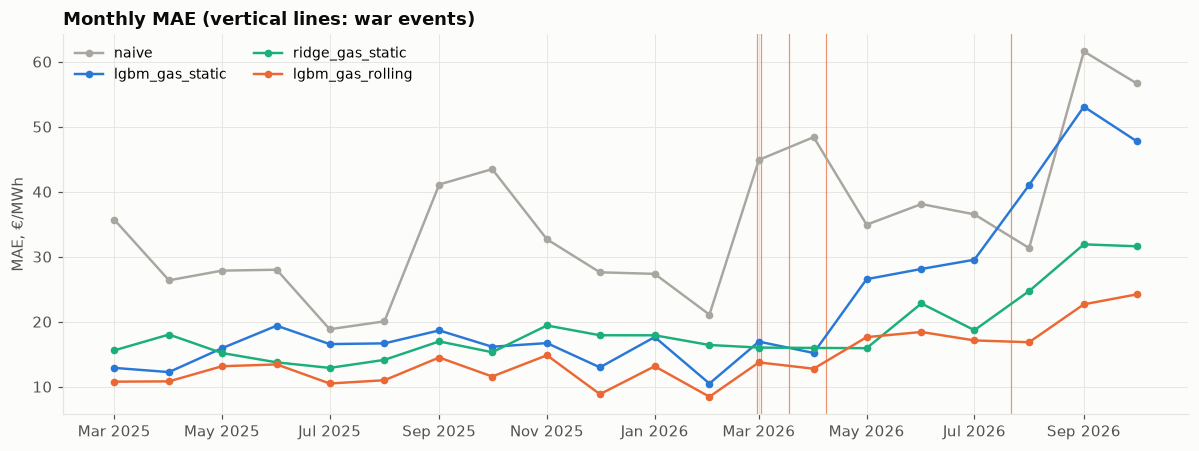

In [4]:
p = pred.copy()
p["month"] = p["delivery_date"].dt.to_period("M").dt.to_timestamp()
monthly = p.groupby("month").apply(lambda g: pd.Series({m: (g["price"] - g[m]).abs().mean() for m in show}))
fig, ax = plt.subplots()
for m in show:
    ax.plot(monthly.index, monthly[m], color=colors[m], marker="o", markersize=4, label=m)
plots.mark_events(ax, label=False)
ax.set_ylabel("MAE, €/MWh"); ax.set_title("Monthly MAE (vertical lines: war events)")
ax.legend(loc="upper left", ncol=2)
plots.date_axis(ax)
fig.tight_layout(); save(fig, "08_monthly_mae")

## 3. Why the static model fails: bias, not noise

Mean error (actual − forecast) > 0 means the model **under-forecasts**. A tree model cannot predict outside the range of
targets it saw in training; when gas moved to levels the model had no recent experience of, it kept forecasting
"pre-war" prices.

,lgbm_gas_static,ridge_gas_static,lgbm_gas_rolling
month,,,
2026-03-01,13.5,5.4,6.8
2026-04-01,7.5,-4.2,-0.6
2026-05-01,23.3,7.8,12.0
2026-06-01,27.0,15.4,11.4
2026-07-01,28.9,12.2,8.2
2026-08-01,40.9,21.0,12.2
2026-09-01,52.5,18.9,8.5
2026-10-01,46.4,25.5,2.7


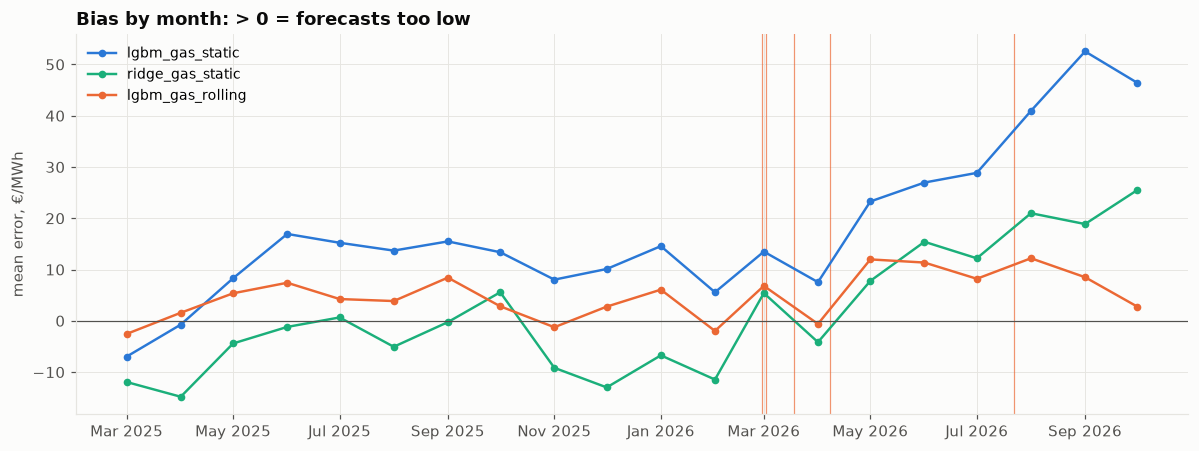

In [5]:
bias = p.groupby("month").apply(lambda g: pd.Series({m: (g["price"] - g[m]).mean() for m in show[1:]}))
fig, ax = plt.subplots()
for m in show[1:]:
    ax.plot(bias.index, bias[m], color=colors[m], marker="o", markersize=4, label=m)
ax.axhline(0, color=INK_2, linewidth=0.8)
plots.mark_events(ax, label=False)
ax.set_ylabel("mean error, €/MWh"); ax.set_title("Bias by month: > 0 = forecasts too low")
ax.legend(loc="upper left")
plots.date_axis(ax)
fig.tight_layout(); save(fig, "09_bias")
bias.loc["2026-03":].round(1)

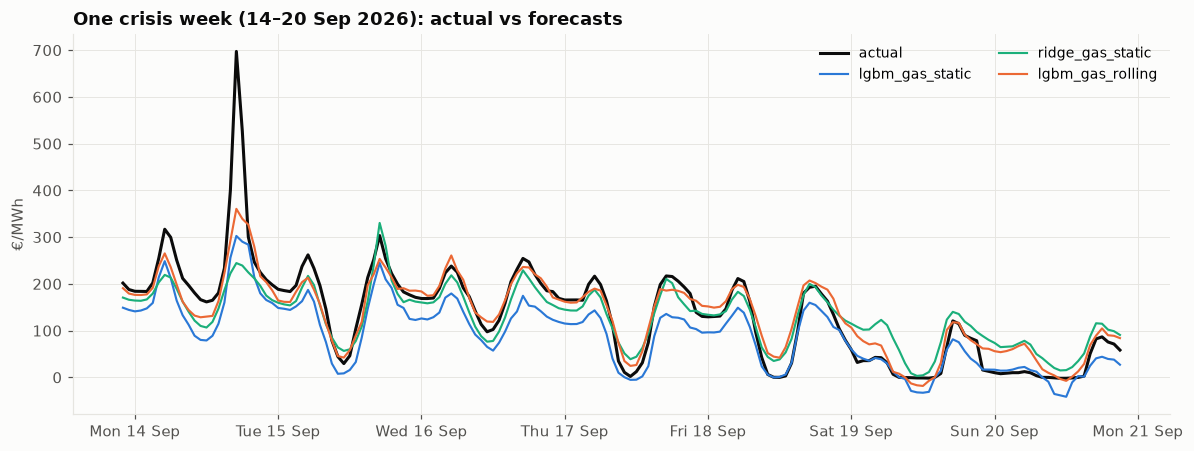

In [6]:
week = p[(p["delivery_date"] >= "2026-09-14") & (p["delivery_date"] <= "2026-09-20")]
fig, ax = plt.subplots()
ax.plot(week.index, week["price"], color="#0b0b0b", linewidth=2, label="actual")
for m in show[1:]:
    ax.plot(week.index, week[m], color=colors[m], linewidth=1.4, label=m)
ax.set_ylabel("€/MWh"); ax.set_title("One crisis week (14–20 Sep 2026): actual vs forecasts")
ax.legend(loc="upper right", ncol=2)
plots.date_axis(ax, "%a %d %b")
fig.tight_layout(); save(fig, "10_sample_week")

## 4. What is a forecast worth? 1 MW / 1 MWh battery

One charge/discharge cycle per day, hours picked from the **forecast**, revenue settled at **actual** prices,
round-trip efficiency 88 %. Benchmark: the same strategy with perfect knowledge of prices.

In [7]:
b = battery.pivot(index="model", columns="period", values=["capture_rate", "revenue_per_day"])
b.columns = [f"{a} · {p}" for a, p in b.columns]
b.sort_values("capture_rate · crisis", ascending=False).round(3)

,capture_rate · crisis,capture_rate · normal,revenue_per_day · crisis,revenue_per_day · normal
model,,,,
ridge_gas_static,0.987,0.949,153.703,94.449
ridge_base_rolling,0.986,0.951,153.543,94.648
ridge_gas_rolling,0.986,0.950,153.573,94.526
ridge_base_static,0.986,0.950,153.579,94.563
lgbm_base_rolling,0.976,0.942,151.976,93.824
lgbm_gas_static,0.976,0.938,151.985,93.426
lgbm_gas_rolling,0.976,0.945,152.043,94.035
lgbm_base_static,0.971,0.939,151.146,93.446
naive,0.918,0.820,142.917,81.602


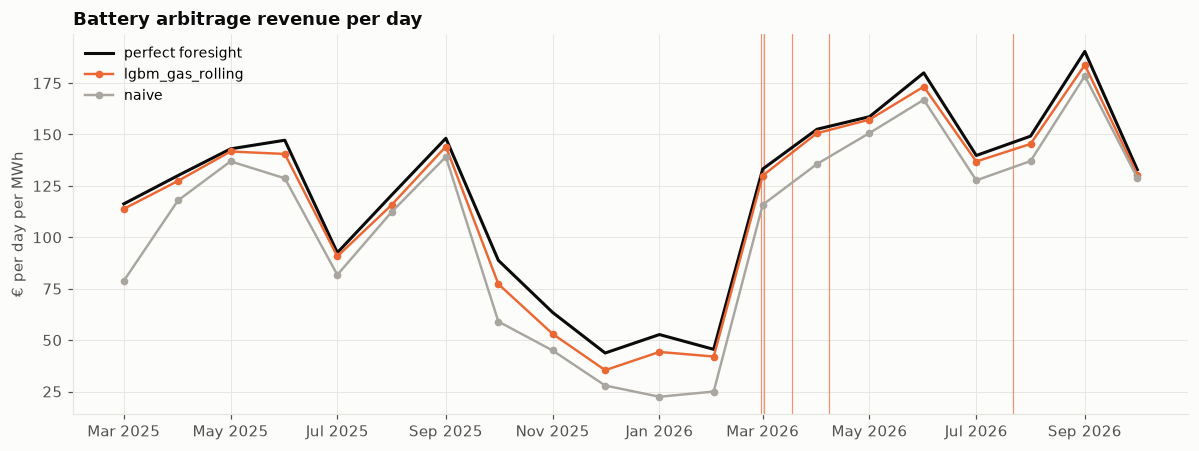

In [8]:
bd = pd.read_parquet(PROCESSED_DIR / "battery_daily.parquet")
bd = bd[bd["model"].isin(["naive", "lgbm_gas_rolling"])]
bd["month"] = pd.to_datetime(bd["date"]).dt.to_period("M").dt.to_timestamp()
rev = bd.groupby(["month", "model"])["revenue"].mean().unstack()
perfect = bd[bd["model"] == "naive"].groupby("month")["perfect"].mean()
fig, ax = plt.subplots()
ax.plot(perfect.index, perfect, color="#0b0b0b", linewidth=2, label="perfect foresight")
ax.plot(rev.index, rev["lgbm_gas_rolling"], color=CRISIS, marker="o", markersize=4, label="lgbm_gas_rolling")
ax.plot(rev.index, rev["naive"], color=MUTED, marker="o", markersize=4, label="naive")
plots.mark_events(ax, label=False)
ax.set_ylabel("€ per day per MWh"); ax.set_title("Battery arbitrage revenue per day")
ax.legend(loc="upper left")
plots.date_axis(ax)
fig.tight_layout(); save(fig, "11_battery_revenue")

Battery revenue is strongly seasonal (small spreads in winter), so the crisis is compared with **the same calendar
window of 2025**, not with the whole normal year:

In [9]:
bd_all = pd.read_parquet(PROCESSED_DIR / "battery_daily.parquet")
bd_all["date"] = pd.to_datetime(bd_all["date"])
last = bd_all["date"].max()
windows = {"same window 2025": bd_all["date"].between(pd.Timestamp("2025-02-28"), last - pd.DateOffset(years=1)),
           "crisis 2026": bd_all["date"] >= pd.Timestamp("2026-02-28")}
rows = []
for name, mask in windows.items():
    for m, g in bd_all[mask].groupby("model"):
        rows.append({"window": name, "model": m, "revenue €/day": g["revenue"].mean(),
                     "perfect €/day": g["perfect"].mean(), "capture": g["revenue"].sum() / g["perfect"].sum()})
same = pd.DataFrame(rows)
same = same[same["model"].isin(["naive", "lgbm_base_static", "lgbm_gas_rolling"])]
same.pivot(index="model", columns="window", values=["revenue €/day", "perfect €/day", "capture"]).round(3)

revenue €/day                  perfect €/day  \
window             crisis 2026 same window 2025   crisis 2026   
model                                                           
lgbm_base_static       151.146          121.148       155.716   
lgbm_gas_rolling       152.043          122.097       155.716   
naive                  142.917          110.896       155.716   

                                      capture                   
window           same window 2025 crisis 2026 same window 2025  
model                                                           
lgbm_base_static          126.099       0.971            0.961  
lgbm_gas_rolling          126.099       0.976            0.968  
naive                     126.099       0.918            0.879

## Takeaways

1. **Accuracy.** In a normal year LightGBM beats the naive benchmark by ~60 % (MAE 11.8 vs 29.2 €/MWh).
2. **The war broke the frozen model.** Trained on 2023 – Feb 2026 and left alone, LightGBM's MAE jumped to ~31 €/MWh
   (×2.3) — even with gas prices as features, because tree models cannot extrapolate beyond the gas levels seen in training.
   A linear model with gas extrapolates better (21.4), and **weekly retraining with gas features** keeps the error at 17.4.
3. **Money ≠ MAE.** For a battery what matters is the *shape* of the day (where the trough and the peak are), not the level.
   Even the broken static model captures ~97 % of perfect-foresight revenue; the naive one only ~88–92 %.
4. **The crisis made flexibility more valuable**: on the same calendar window, perfect-foresight battery revenue rose
   from ~126 to ~156 € per day per MWh (+23 %), because gas raised evening peaks much more than solar-driven midday prices.